## <span style="color:#1F4E79;">__Parameter Recovery in the Bradley-Terry Model__</span>
__*This notebook studies how accurately the true parameters can be recovered from simulated comparison data.*__

In [6]:
# Import the libraries and reusable Bradley–Terry functions required in this notebook.
# Also to set a fixed random seed and consistent display settings for reproducible experiments.
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bradley_terry import (
    center_parameters,
    estimate_parameters_with_gradient_descent,
    generate_uniform_comparison_data,
    parameter_recovery_error,
    run_parameter_recovery_trials
)
SEED=20260831
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision",4)

##### Reusable Bradley–Terry Functions

| Function | Purpose |
|---|---|
| `center_parameters()` | Shifts parameters so their mean is zero. |
| `generate_uniform_comparison_data()` | Generates observations as `(winner, loser)` pairs. |
| `estimate_parameters_with_gradient_descent()` | Estimates parameters by minimizing the NLL. |
| `parameter_recovery_error()` | Calculates RMSE between true and estimated parameters. |
| `run_parameter_recovery_trials()` | Repeats an experiment across multiple random datasets. |

In [3]:
# Define a fixed set of 10 centred true parameters for the baseline experiment.
number_of_items=10
true_parameters=np.linspace(
    -1.5,
    1.5,
    number_of_items
)
true_parameters=center_parameters(
    true_parameters
)
true_parameter_table=pd.DataFrame({
    "item":np.arange(number_of_items),
    "true_parameter":true_parameters
})
true_parameter_table

,item,true_parameter
0,0,-1.5000
1,1,-1.1667
2,2,-0.8333
3,3,-0.5000
4,4,-0.1667
5,5,0.1667
6,6,0.5000
7,7,0.8333
8,8,1.1667
9,9,1.5000


In [4]:
# Generate a reproducible baseline dataset of paired winner–loser observations.
number_of_comparisons=1000
rng=np.random.default_rng(SEED)
comparisons=generate_uniform_comparison_data(
    true_parameters,
    number_of_comparisons,
    rng
)
comparison_table=pd.DataFrame(
    comparisons,
    columns=["winner","loser"]
)
comparison_table.head(10)

,winner,loser
0,1,3
1,9,5
2,9,3
3,6,3
4,8,5
5,2,1
6,5,3
7,3,1
8,7,3
9,7,5


In [10]:
# (Basic EDA) Summarise the wins, appearances and observed win rate of every item.

comparison_array=np.asarray(
    comparisons,
    dtype=int
)

wins=np.bincount(
    comparison_array[:,0],
    minlength=number_of_items
)

appearances=np.bincount(
    comparison_array.flatten(),
    minlength=number_of_items
)

observed_win_rate=wins/appearances

comparison_summary_table=pd.DataFrame({
    "item":np.arange(number_of_items),
    "wins":wins,
    "appearances":appearances,
    "observed_win_rate":observed_win_rate,
    "true_parameter":true_parameters
})

comparison_summary_table

,item,wins,appearances,observed_win_rate,true_parameter
0,0,44,209,0.2105,-1.5000
1,1,39,181,0.2155,-1.1667
2,2,58,177,0.3277,-0.8333
3,3,76,211,0.3602,-0.5000
4,4,87,203,0.4286,-0.1667
5,5,118,206,0.5728,0.1667
6,6,117,205,0.5707,0.5000
7,7,148,205,0.7220,0.8333
8,8,161,215,0.7488,1.1667
9,9,152,188,0.8085,1.5000


In [7]:
# Estimate the unknown parameters and record the optimization time and NLL history.

learning_rate=0.1
maximum_iterations=1000

start_time=perf_counter()

estimated_parameters,nll_history=(
    estimate_parameters_with_gradient_descent(
        number_of_items=number_of_items,
        comparisons=comparisons,
        learning_rate=learning_rate,
        maximum_iterations=maximum_iterations
    )
)

estimation_time=perf_counter()-start_time

print(f"Initial average NLL: {nll_history[0]:.4f}")
print(f"Final average NLL:   {nll_history[-1]:.4f}")
print(f"Estimation time:     {estimation_time:.4f} seconds")

Initial average NLL: 0.6931
Final average NLL:   0.5189
Estimation time:     0.3725 seconds


In [8]:
# Compare the true and estimated parameters and calculate the baseline recovery error.

recovery_error=parameter_recovery_error(
    true_parameters,
    estimated_parameters
)

parameter_comparison_table=pd.DataFrame({
    "item":np.arange(number_of_items),
    "true_parameter":true_parameters,
    "estimated_parameter":estimated_parameters,
    "estimation_error":(
        estimated_parameters-true_parameters
    )
})

display(parameter_comparison_table)

print(f"Parameter-recovery RMSE: {recovery_error:.4f}")

,item,true_parameter,estimated_parameter,estimation_error
0,0,-1.5000,-1.3118,0.1882
1,1,-1.1667,-1.3044,-0.1378
2,2,-0.8333,-0.7368,0.0966
3,3,-0.5000,-0.5401,-0.0401
4,4,-0.1667,-0.1967,-0.0300
5,5,0.1667,0.2881,0.1215
6,6,0.5000,0.3050,-0.1950
7,7,0.8333,0.9360,0.1026
8,8,1.1667,1.1445,-0.0222
9,9,1.5000,1.4162,-0.0838


Parameter-recovery RMSE: 0.1171


#### Experiment 1: Effect of the Number of Comparisons
Here,the experiment studies how the amount of observed comparison data affects parameter recovery.
The number of items, true parameters, sampling method and optimization settings are kept fixed. Only the number of pairwise comparisons is changed.

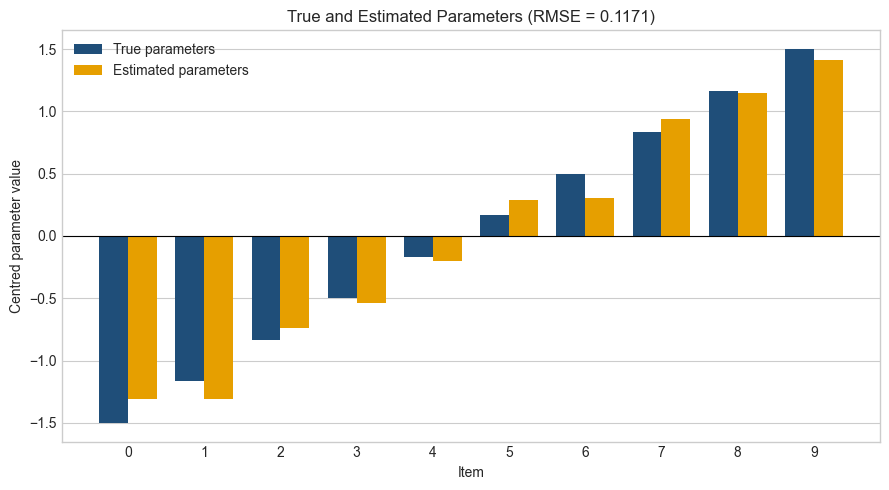

In [ ]:
# Plot the true and estimated parameters for each item.
item_indices=np.arange(number_of_items)
bar_width=0.38

fig,ax=plt.subplots(
    figsize=(9,5)
)

ax.bar(
    item_indices-bar_width/2,
    true_parameters,
    width=bar_width,
    label="True parameters",
    color="#1F4E79"
)

ax.bar(
    item_indices+bar_width/2,
    estimated_parameters,
    width=bar_width,
    label="Estimated parameters",
    color="#E69F00"
)

ax.axhline(
    0,
    color="black",
    linewidth=0.8
)
ax.set_xlabel("Item")
ax.set_ylabel("Centred parameter value")
ax.set_title(
    f"True and Estimated Parameters (RMSE = {recovery_error:.4f})"
)
ax.set_xticks(item_indices)
ax.legend()
ax.grid(axis="x",visible=False)
plt.tight_layout()
plt.show()

In [12]:
# Repeat parameter recovery for different numbers of observed comparisons.

comparison_counts=np.array([
    50,
    100,
    200,
    500,
    1000,
    2000,
    5000
])

number_of_runs=20

comparison_errors={}
comparison_results=[]

for comparison_count in comparison_counts:
    start_time=perf_counter()

    recovery_errors=run_parameter_recovery_trials(
        true_parameters=true_parameters,
        number_of_comparisons=int(comparison_count),
        number_of_runs=number_of_runs,
        seed=SEED+int(comparison_count),
        learning_rate=learning_rate,
        maximum_iterations=maximum_iterations
    )

    elapsed_time=perf_counter()-start_time

    comparison_errors[int(comparison_count)]=recovery_errors

    comparison_results.append({
        "number_of_comparisons":int(comparison_count),
        "mean_recovery_error":np.mean(recovery_errors),
        "standard_deviation":np.std(
            recovery_errors,
            ddof=1
        ),
        "runtime_seconds":elapsed_time
    })

    print(
        f"Completed {comparison_count} comparisons "
        f"in {elapsed_time:.2f} seconds"
    )

comparison_results_table=pd.DataFrame(
    comparison_results
)

comparison_results_table

Completed 50 comparisons in 1.28 seconds
Completed 100 comparisons in 1.58 seconds
Completed 200 comparisons in 2.21 seconds
Completed 500 comparisons in 4.02 seconds
Completed 1000 comparisons in 7.06 seconds
Completed 2000 comparisons in 13.97 seconds
Completed 5000 comparisons in 33.02 seconds


,number_of_comparisons,mean_recovery_error,standard_deviation,runtime_seconds
0,50,0.6949,0.2220,1.2755
1,100,0.4730,0.1142,1.5761
2,200,0.3180,0.0810,2.2083
3,500,0.2047,0.0593,4.0193
4,1000,0.1495,0.0338,7.0622
5,2000,0.1060,0.0250,13.9723
6,5000,0.0813,0.0154,33.0228


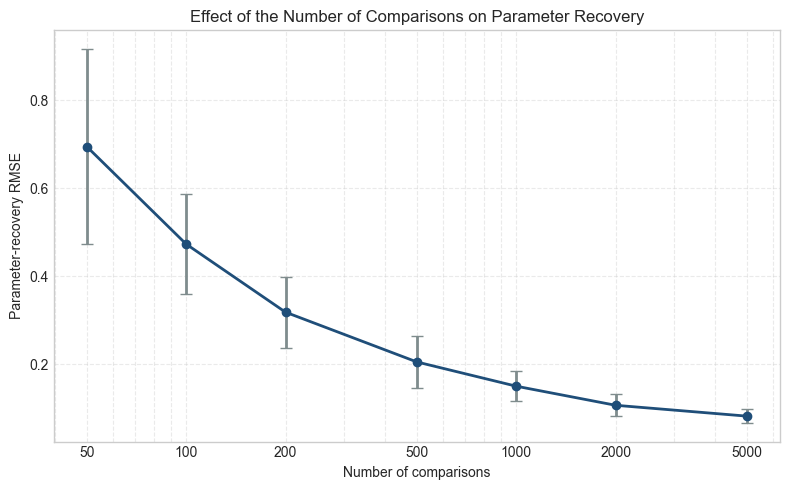

In [13]:
# Plot the mean recovery error with one-standard-deviation error bars.

fig,ax=plt.subplots(
    figsize=(8,5)
)

ax.errorbar(
    comparison_results_table["number_of_comparisons"],
    comparison_results_table["mean_recovery_error"],
    yerr=comparison_results_table["standard_deviation"],
    marker="o",
    markersize=6,
    linewidth=2,
    capsize=4,
    color="#1F4E79",
    ecolor="#7F8C8D"
)

ax.set_xscale("log")

ax.set_xticks(comparison_counts)
ax.set_xticklabels(comparison_counts)

ax.set_xlabel("Number of comparisons")
ax.set_ylabel("Parameter-recovery RMSE")
ax.set_title(
    "Effect of the Number of Comparisons on Parameter Recovery"
)

ax.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

In [ ]:
# Extend the experiment to larger datasets to examine diminishing returns.(maybe statistical convergence)

additional_comparison_counts=np.array([
    10000,
    20000
])

additional_results=[]

for comparison_count in additional_comparison_counts:
    start_time=perf_counter()

    recovery_errors=run_parameter_recovery_trials(
        true_parameters=true_parameters,
        number_of_comparisons=int(comparison_count),
        number_of_runs=number_of_runs,
        seed=SEED+int(comparison_count),
        learning_rate=learning_rate,
        maximum_iterations=maximum_iterations
    )

    elapsed_time=perf_counter()-start_time

    comparison_errors[int(comparison_count)]=recovery_errors

    additional_results.append({
        "number_of_comparisons":int(comparison_count),
        "mean_recovery_error":np.mean(recovery_errors),
        "standard_deviation":np.std(
            recovery_errors,
            ddof=1
        ),
        "runtime_seconds":elapsed_time
    })

    print(
        f"Completed {comparison_count} comparisons "
        f"in {elapsed_time:.2f} seconds"
    )

comparison_results_table=(
    pd.concat(
        [
            comparison_results_table,
            pd.DataFrame(additional_results)
        ],
        ignore_index=True
    )
    .drop_duplicates(
        subset="number_of_comparisons",
        keep="last"
    )
    .sort_values("number_of_comparisons")
    .reset_index(drop=True)
)

comparison_counts=(
    comparison_results_table[
        "number_of_comparisons"
    ].to_numpy()
)

comparison_results_table

Completed 10000 comparisons in 65.31 seconds
Completed 20000 comparisons in 127.82 seconds


,number_of_comparisons,mean_recovery_error,standard_deviation,runtime_seconds
0,50,0.6949,0.2220,1.2755
1,100,0.4730,0.1142,1.5761
2,200,0.3180,0.0810,2.2083
3,500,0.2047,0.0593,4.0193
4,1000,0.1495,0.0338,7.0622
5,2000,0.1060,0.0250,13.9723
6,5000,0.0813,0.0154,33.0228
7,10000,0.0616,0.0110,65.3106
8,20000,0.0556,0.0084,127.8235


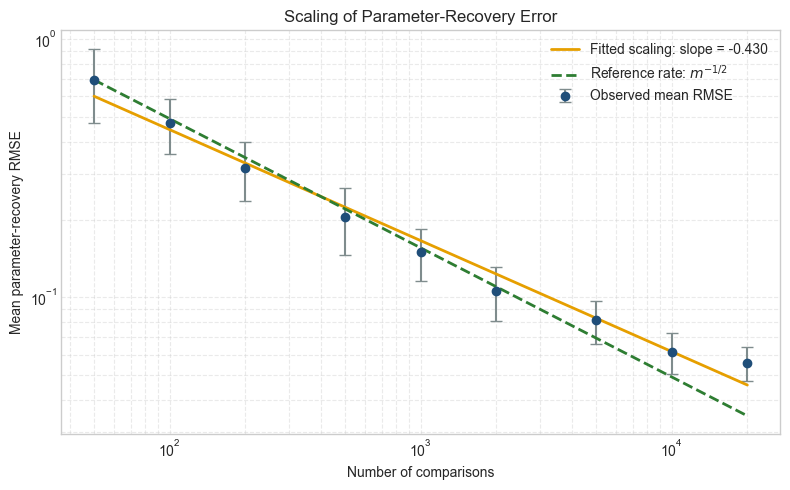

Estimated log-log slope: -0.4298


In [15]:
# Plot the recovery-error scaling and compare it with the theoretical inverse-square-root rate.

comparison_values=(
    comparison_results_table[
        "number_of_comparisons"
    ].to_numpy()
)

mean_errors=(
    comparison_results_table[
        "mean_recovery_error"
    ].to_numpy()
)

error_standard_deviations=(
    comparison_results_table[
        "standard_deviation"
    ].to_numpy()
)

fitted_slope,fitted_intercept=np.polyfit(
    np.log(comparison_values),
    np.log(mean_errors),
    deg=1
)

fitted_errors=np.exp(
    fitted_intercept
)*comparison_values**fitted_slope

inverse_square_root_reference=(
    mean_errors[0]
    *(
        comparison_values/comparison_values[0]
    )**(-0.5)
)

fig,ax=plt.subplots(
    figsize=(8,5)
)

ax.errorbar(
    comparison_values,
    mean_errors,
    yerr=error_standard_deviations,
    fmt="o",
    markersize=6,
    capsize=4,
    color="#1F4E79",
    ecolor="#7F8C8D",
    label="Observed mean RMSE"
)

ax.plot(
    comparison_values,
    fitted_errors,
    linewidth=2,
    color="#E69F00",
    label=f"Fitted scaling: slope = {fitted_slope:.3f}"
)

ax.plot(
    comparison_values,
    inverse_square_root_reference,
    linewidth=2,
    linestyle="--",
    color="#2E7D32",
    label=r"Reference rate: $m^{-1/2}$"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Number of comparisons")
ax.set_ylabel("Mean parameter-recovery RMSE")
ax.set_title("Scaling of Parameter-Recovery Error")

ax.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

ax.legend()

plt.tight_layout()
plt.show()

print(f"Estimated log-log slope: {fitted_slope:.4f}")

#### Inference of the above graph

Recovery error and its variation decrease as more comparisons are observed. The fitted slope of \(-0.430\) is reasonably close to the theoretical root of 'm' rate(number of comparisons), suggesting approximate inverse-square-root scaling with diminishing returns. This conclusion applies to the current experimental settings and does not establish optimizer convergence.


## Experiment 2: Effect of the Number of Items

This experiment studies how parameter recovery changes as the number of items increases.
Therefore, for $m$ comparisons, the total number of item appearances is $2m$. With $n$ items, the average number of appearances per item is

$$
\frac{2m}{n}.
$$

To avoid giving larger item sets less data per item, the number of comparisons is adjusted so that every setting has the same expected number of appearances per item.



In [17]:
# Define item-set sizes while keeping the average appearances per item fixed.

item_counts=np.array([
    5,
    10,
    20,
    40,
    80
])

target_appearances_per_item=200

item_comparison_counts=(
    item_counts
    *target_appearances_per_item
    //2
)

item_experiment_settings=pd.DataFrame({
    "number_of_items":item_counts,
    "number_of_comparisons":item_comparison_counts,
    "average_appearances_per_item":(
        2*item_comparison_counts/item_counts
    )
})

item_experiment_settings

,number_of_items,number_of_comparisons,average_appearances_per_item
0,5,500,200.0
1,10,1000,200.0
2,20,2000,200.0
3,40,4000,200.0
4,80,8000,200.0


In [18]:
# Repeat parameter recovery for different item-set sizes with equal data per item.

item_errors={}
item_true_parameters={}
item_results=[]

for item_count,comparison_count in zip(
    item_counts,
    item_comparison_counts
):
    current_true_parameters=np.linspace(
        -1.5,
        1.5,
        int(item_count)
    )

    current_true_parameters=center_parameters(
        current_true_parameters
    )

    start_time=perf_counter()

    recovery_errors=run_parameter_recovery_trials(
        true_parameters=current_true_parameters,
        number_of_comparisons=int(comparison_count),
        number_of_runs=number_of_runs,
        seed=SEED+100000+int(item_count),
        learning_rate=learning_rate,
        maximum_iterations=maximum_iterations
    )

    elapsed_time=perf_counter()-start_time

    item_errors[int(item_count)]=recovery_errors
    item_true_parameters[int(item_count)]=(
        current_true_parameters
    )

    item_results.append({
        "number_of_items":int(item_count),
        "number_of_comparisons":int(comparison_count),
        "mean_recovery_error":np.mean(
            recovery_errors
        ),
        "standard_deviation":np.std(
            recovery_errors,
            ddof=1
        ),
        "runtime_seconds":elapsed_time
    })

    print(
        f"Completed {item_count} items with "
        f"{comparison_count} comparisons "
        f"in {elapsed_time:.2f} seconds"
    )

item_results_table=pd.DataFrame(
    item_results
)

item_results_table

Completed 5 items with 500 comparisons in 4.27 seconds
Completed 10 items with 1000 comparisons in 7.26 seconds
Completed 20 items with 2000 comparisons in 13.54 seconds
Completed 40 items with 4000 comparisons in 26.14 seconds
Completed 80 items with 8000 comparisons in 51.89 seconds


,number_of_items,number_of_comparisons,mean_recovery_error,standard_deviation,runtime_seconds
0,5,500,0.1379,0.0554,4.2694
1,10,1000,0.1463,0.0366,7.2581
2,20,2000,0.2150,0.0348,13.5412
3,40,4000,0.3775,0.0149,26.1442
4,80,8000,0.5538,0.0050,51.8940
